# Ayushman Bharat Healthcare Analytics: Analysis of Hospital Accessibility and Services

Course: Data Analytics using Python (CSL-0312) | ITM University Gwalior

Team: Krishna Sharma, Jacky Rayeen, Tamash Sahu | Mentor: Dr. Sanjay Jain

Place `Data_sets_of_data_analytics.xls` in the same folder as this notebook, then run all cells.

# 1. INTRODUCTION

## Ayushman Bharat Healthcare Analytics

### 1.1 Problem Statement

The distribution of PM-JAY empanelled hospitals varies across different districts of Madhya Pradesh. This project analyses hospital availability, hospital categories and specialty distribution to understand healthcare accessibility across the state.

### 1.2 Objectives

- To analyse district-wise hospital distribution.
- To identify districts with the highest and lowest hospital counts.
- To study public and private hospital distribution.
- To analyse the availability of medical specialties.
- To identify districts with comparatively low hospital coverage.
- To perform statistical analysis of healthcare data.
- To present findings through data visualizations.

### 1.3 Scope

The project analyses PM-JAY empanelled hospital records across Madhya Pradesh using Python-based data analytics techniques.

### 1.4 Tools and Technologies

- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

### 1.5 Project Approach

Data Understanding → Data Cleaning → Data Preprocessing → EDA → Data Visualization → Statistical Analysis → Key Findings → Conclusion.

## 1. IMPORT LIBRARIES

In [65]:
# IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Ignore unnecessary warnings
warnings.filterwarnings('ignore')

# Visualization settings
plt.style.use('default')
sns.set_theme(style="whitegrid")

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)

print("All required libraries imported successfully!")

All required libraries imported successfully!


## 2. LOAD DATASET

In [66]:
# Load the original Excel dataset
file_path = "/content/Data_sets_of_data_analytics.xls"

df = pd.read_excel(file_path)

# Display dataset loading information
print("Dataset loaded successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

# Display first five records
display(df.head())

Dataset loaded successfully!
Total Rows: 1230
Total Columns: 18


,Sno,Hospital Id,Hospital Name,State,District,Unnamed: 5,Unnamed: 6,Unnamed: 7,Hospital Contact,Specialities Selected,Hospital Type,Empanelment Type,Submitted Date,Status Updated Date,Application Status,OnBoarded For Convergence Scheme,Upgraded Specialities,Current Specialities
0,1,HOSP23G00360,Jay Prakash District Hospital Bhopal,MADHYA PRADESH,BHOPAL,NaN,NaN,NaN,9425004150,"M1,M7,M2,S1,S14,S16,S2,S3,S4,S5,",Public,PMJAY,-NA-,-NA-,Hospital Approved for Empanelment,No,NaN,"M1, M7, M2, S1, S14, S16, S2, S3, S4, S5"
1,2,HOSP23G00853,BUNDELKHAND MEDICAL COLLEGE SAGAR,MADHYA PRADESH,SAGAR,NaN,NaN,NaN,8770058945,"M1,M7,M2,S1,S16,S2,S3,S4,S5,",Public,PMJAY,-NA-,-NA-,Hospital Approved for Empanelment,No,NaN,"M1, M7, M2, S1, S16, S2, S3, S4, S5"
2,3,HOSP23G01370,SGMH AND GMH Rewa,MADHYA PRADESH,REWA,NaN,NaN,NaN,9340314708,"M1,M1,M7,M2,M3,M8,S1,S10,S11,S12,S14,S16,S2,S3...",Public,PMJAY,-NA-,-NA-,Hospital Approved for Empanelment,No,NaN,"M1, M7, M2, M3, M8, S1, S10, S11, S12, S14, S1..."
3,4,HOSP23G01396,HAMIDIA HOSPITAL,MADHYA PRADESH,BHOPAL,NaN,NaN,NaN,9312872529,"M1,M1,M2,S8,M1,M7,M1,S7,M2,M3,M4,M5,M6,M8,S1,S...",Public,PMJAY,-NA-,-NA-,Hospital Approved for Empanelment,No,NaN,"M1, M2, S8, M7, S7, M3, M4, M5, M6, M8, S1, S1..."
4,5,HOSP23G01412,MAHARAJA YASHWANT RAO,MADHYA PRADESH,INDORE,NaN,NaN,NaN,8770115981,"M1,M1,M2,S8,M1,M7,M1,S7,M2,M3,M4,M5,M6,M8,S1,S...",Public,PMJAY,-NA-,-NA-,Hospital Approved for Empanelment,No,NaN,"M1, M2, S8, M7, S7, M3, M4, M5, M6, M8, S1, S1..."


## 3. DATA UNDERSTANDING

In [67]:
# 1. Dataset dimensions
print("Dataset Shape:", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

# 2. Column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Dataset information
print("\nDataset Information:")
df.info()

# 4. First five records
print("\nFirst Five Records:")
display(df.head())

# 5. Last five records
print("\nLast Five Records:")
display(df.tail())

# 6. Data types
print("\nColumn Data Types:")
display(df.dtypes)

# 7. Statistical summary
print("\nStatistical Summary:")
display(df.describe(include='all'))


Dataset Shape: (1230, 18)
Total Rows: 1230
Total Columns: 18

Column Names:
['Sno', 'Hospital Id', 'Hospital Name', 'State', 'District', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Hospital Contact', 'Specialities Selected', 'Hospital Type', 'Empanelment Type', 'Submitted Date', 'Status Updated Date', 'Application Status', 'OnBoarded For Convergence Scheme', 'Upgraded Specialities', 'Current Specialities']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1230 entries, 0 to 1229
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Sno                               1230 non-null   int64  
 1   Hospital Id                       1230 non-null   object 
 2   Hospital Name                     1230 non-null   object 
 3   State                             1230 non-null   object 
 4   District                          1230 non-null   object 
 5   Unnamed: 5      

,Sno,Hospital Id,Hospital Name,State,District,Unnamed: 5,Unnamed: 6,Unnamed: 7,Hospital Contact,Specialities Selected,Hospital Type,Empanelment Type,Submitted Date,Status Updated Date,Application Status,OnBoarded For Convergence Scheme,Upgraded Specialities,Current Specialities
0,1,HOSP23G00360,Jay Prakash District Hospital Bhopal,MADHYA PRADESH,BHOPAL,NaN,NaN,NaN,9425004150,"M1,M7,M2,S1,S14,S16,S2,S3,S4,S5,",Public,PMJAY,-NA-,-NA-,Hospital Approved for Empanelment,No,NaN,"M1, M7, M2, S1, S14, S16, S2, S3, S4, S5"
1,2,HOSP23G00853,BUNDELKHAND MEDICAL COLLEGE SAGAR,MADHYA PRADESH,SAGAR,NaN,NaN,NaN,8770058945,"M1,M7,M2,S1,S16,S2,S3,S4,S5,",Public,PMJAY,-NA-,-NA-,Hospital Approved for Empanelment,No,NaN,"M1, M7, M2, S1, S16, S2, S3, S4, S5"
2,3,HOSP23G01370,SGMH AND GMH Rewa,MADHYA PRADESH,REWA,NaN,NaN,NaN,9340314708,"M1,M1,M7,M2,M3,M8,S1,S10,S11,S12,S14,S16,S2,S3...",Public,PMJAY,-NA-,-NA-,Hospital Approved for Empanelment,No,NaN,"M1, M7, M2, M3, M8, S1, S10, S11, S12, S14, S1..."
3,4,HOSP23G01396,HAMIDIA HOSPITAL,MADHYA PRADESH,BHOPAL,NaN,NaN,NaN,9312872529,"M1,M1,M2,S8,M1,M7,M1,S7,M2,M3,M4,M5,M6,M8,S1,S...",Public,PMJAY,-NA-,-NA-,Hospital Approved for Empanelment,No,NaN,"M1, M2, S8, M7, S7, M3, M4, M5, M6, M8, S1, S1..."
4,5,HOSP23G01412,MAHARAJA YASHWANT RAO,MADHYA PRADESH,INDORE,NaN,NaN,NaN,8770115981,"M1,M1,M2,S8,M1,M7,M1,S7,M2,M3,M4,M5,M6,M8,S1,S...",Public,PMJAY,-NA-,-NA-,Hospital Approved for Empanelment,No,NaN,"M1, M2, S8, M7, S7, M3, M4, M5, M6, M8, S1, S1..."



Last Five Records:


,Sno,Hospital Id,Hospital Name,State,District,Unnamed: 5,Unnamed: 6,Unnamed: 7,Hospital Contact,Specialities Selected,Hospital Type,Empanelment Type,Submitted Date,Status Updated Date,Application Status,OnBoarded For Convergence Scheme,Upgraded Specialities,Current Specialities
1225,1226,LAB23396130015,venus scan and research centre bhopal,MADHYA PRADESH,BHOPAL,NaN,NaN,NaN,9893411107,NaN,NaN,Only CGHS,-NA-,-NA-,Hospital Approved for Empanelment,No,NaN,-NA-
1226,1227,LAB23396206224,Thyrocare Technologies Limited,MADHYA PRADESH,BHOPAL,NaN,NaN,NaN,7506756776,NaN,NaN,Only CGHS,-NA-,-NA-,Hospital Approved for Empanelment,No,NaN,-NA-
1227,1228,LAB23410136007,Healthcare Diagnostic,MADHYA PRADESH,INDORE,NaN,NaN,NaN,7898017706,NaN,NaN,Only CGHS,-NA-,-NA-,Hospital Approved for Empanelment,No,NaN,-NA-
1228,1229,LAB23410209554,Centrapath Labs Private Limited,MADHYA PRADESH,INDORE,NaN,NaN,NaN,9425048863,NaN,NaN,Only CGHS,-NA-,-NA-,Hospital Approved for Empanelment,No,NaN,-NA-
1229,1230,LAB23411129837,Sanya Hospital and diagnostics pvt ltd,MADHYA PRADESH,JABALPUR,NaN,NaN,NaN,9826675766,NaN,NaN,Only CGHS,-NA-,-NA-,Hospital Approved for Empanelment,Yes,NaN,-NA-



Column Data Types:


,0
Sno,int64
Hospital Id,object
Hospital Name,object
State,object
District,object
Unnamed: 5,float64
Unnamed: 6,float64
Unnamed: 7,float64
Hospital Contact,int64
Specialities Selected,object



Statistical Summary:


,Sno,Hospital Id,Hospital Name,State,District,Unnamed: 5,Unnamed: 6,Unnamed: 7,Hospital Contact,Specialities Selected,Hospital Type,Empanelment Type,Submitted Date,Status Updated Date,Application Status,OnBoarded For Convergence Scheme,Upgraded Specialities,Current Specialities
count,1230.000000,1230,1230,1230,1230,0.0,0.0,0.0,1.230000e+03,1214,1208,1230,1230,1230,1230,1230,306,1230
unique,NaN,1230,1195,1,51,NaN,NaN,NaN,NaN,550,4,4,1,1,1,2,170,662
top,NaN,HOSP23G00360,SANJEEVANI HOSPITAL,MADHYA PRADESH,BHOPAL,NaN,NaN,NaN,NaN,"M1,M7,",Private(For Profit),PMJAY,-NA-,-NA-,Hospital Approved for Empanelment,No,"MG,","M1, M7"
freq,NaN,1,4,1230,256,NaN,NaN,NaN,NaN,181,611,1065,1230,1230,1230,1155,22,118
mean,615.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.977603e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,355.214724,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.476643e+08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.232005e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,308.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.319783e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,615.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.340285e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,922.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.754796e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4.DATA CLEANING

In [68]:
df_clean = df.copy()

df_clean.columns = df_clean.columns.astype(str).str.strip()

df_clean = df_clean.loc[
    :, ~df_clean.columns.str.contains(r'^Unnamed:', case=False)
]

df_clean.dropna(axis=1, how='all', inplace=True)

if 'Hospital Id' in df_clean.columns:
    df_clean.drop_duplicates(
        subset=['Hospital Id'],
        keep='first',
        inplace=True
    )
else:
    df_clean.drop_duplicates(inplace=True)

if 'Hospital Type' in df_clean.columns:
    df_clean['Hospital Type'] = (
        df_clean['Hospital Type'].fillna('Not Specified')
    )

if 'Upgraded Specialities' in df_clean.columns:
    df_clean['Upgraded Specialities'] = (
        df_clean['Upgraded Specialities'].fillna('Not Specified')
    )

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nRemaining Missing Values:")
display(df_clean.isnull().sum())

print("\nRemaining Duplicate Hospital IDs:")
if 'Hospital Id' in df_clean.columns:
    print(df_clean['Hospital Id'].duplicated().sum())

print("\nData Cleaning Completed!")

if 'Specialities Selected' in df_clean.columns:
    df_clean['Specialities Selected'] = (
        df_clean['Specialities Selected'].fillna('Not Specified')
    )

print("Missing Values After Final Cleaning:")
display(df_clean.isnull().sum())

print("Final Shape:", df_clean.shape)


Original Dataset Shape: (1230, 18)
Cleaned Dataset Shape: (1230, 15)

Remaining Missing Values:


,0
Sno,0
Hospital Id,0
Hospital Name,0
State,0
District,0
Hospital Contact,0
Specialities Selected,16
Hospital Type,0
Empanelment Type,0
Submitted Date,0



Remaining Duplicate Hospital IDs:
0

Data Cleaning Completed!
Missing Values After Final Cleaning:


,0
Sno,0
Hospital Id,0
Hospital Name,0
State,0
District,0
Hospital Contact,0
Specialities Selected,0
Hospital Type,0
Empanelment Type,0
Submitted Date,0


Final Shape: (1230, 15)


## 5. DATA PREPROCESSING

In [69]:
df_processed = df_clean.copy()

text_columns = [
    'Hospital Name',
    'District',
    'Hospital Type',
    'Empanelment Type'
]

for col in text_columns:
    if col in df_processed.columns:
        df_processed[col] = (
            df_processed[col]
            .astype('string')
            .str.strip()
            .str.replace(r'\s+', ' ', regex=True)
        )

for col in ['Hospital Name', 'District']:
    if col in df_processed.columns:
        df_processed[col] = df_processed[col].str.title()

if 'Current Specialities' in df_processed.columns:
    df_processed.rename(
        columns={'Current Specialities': 'Specialities'},
        inplace=True
    )

if 'OnBoarded For Convergence Scheme' in df_processed.columns:
    df_processed.rename(
        columns={'OnBoarded For Convergence Scheme': 'Convergence Scheme'},
        inplace=True
    )

if 'Specialities' in df_processed.columns:
    df_processed['Specialities'] = (
        df_processed['Specialities'].fillna('')
    )

    df_processed['Num Specialities'] = (
        df_processed['Specialities']
        .apply(lambda x: len([s for s in str(x).split(',') if s.strip()]))
    )

    df_processed['M Codes'] = (
        df_processed['Specialities']
        .str.findall(r'M\d+')
        .apply(lambda x: ', '.join(x))
    )

    df_processed['S Codes'] = (
        df_processed['Specialities']
        .str.findall(r'S\d+')
        .apply(lambda x: ', '.join(x))
    )

print("Data Preprocessing Completed!")
print("Processed Dataset Shape:", df_processed.shape)

display(df_processed.head())

Data Preprocessing Completed!
Processed Dataset Shape: (1230, 18)


,Sno,Hospital Id,Hospital Name,State,District,Hospital Contact,Specialities Selected,Hospital Type,Empanelment Type,Submitted Date,Status Updated Date,Application Status,Convergence Scheme,Upgraded Specialities,Specialities,Num Specialities,M Codes,S Codes
0,1,HOSP23G00360,Jay Prakash District Hospital Bhopal,MADHYA PRADESH,Bhopal,9425004150,"M1,M7,M2,S1,S14,S16,S2,S3,S4,S5,",Public,PMJAY,-NA-,-NA-,Hospital Approved for Empanelment,No,Not Specified,"M1, M7, M2, S1, S14, S16, S2, S3, S4, S5",10,"M1, M7, M2","S1, S14, S16, S2, S3, S4, S5"
1,2,HOSP23G00853,Bundelkhand Medical College Sagar,MADHYA PRADESH,Sagar,8770058945,"M1,M7,M2,S1,S16,S2,S3,S4,S5,",Public,PMJAY,-NA-,-NA-,Hospital Approved for Empanelment,No,Not Specified,"M1, M7, M2, S1, S16, S2, S3, S4, S5",9,"M1, M7, M2","S1, S16, S2, S3, S4, S5"
2,3,HOSP23G01370,Sgmh And Gmh Rewa,MADHYA PRADESH,Rewa,9340314708,"M1,M1,M7,M2,M3,M8,S1,S10,S11,S12,S14,S16,S2,S3...",Public,PMJAY,-NA-,-NA-,Hospital Approved for Empanelment,No,Not Specified,"M1, M7, M2, M3, M8, S1, S10, S11, S12, S14, S1...",19,"M1, M7, M2, M3, M8","S1, S10, S11, S12, S14, S16, S2, S3, S4, S5, S..."
3,4,HOSP23G01396,Hamidia Hospital,MADHYA PRADESH,Bhopal,9312872529,"M1,M1,M2,S8,M1,M7,M1,S7,M2,M3,M4,M5,M6,M8,S1,S...",Public,PMJAY,-NA-,-NA-,Hospital Approved for Empanelment,No,Not Specified,"M1, M2, S8, M7, S7, M3, M4, M5, M6, M8, S1, S1...",24,"M1, M2, M7, M3, M4, M5, M6, M8","S8, S7, S1, S10, S11, S12, S13, S14, S15, S16,..."
4,5,HOSP23G01412,Maharaja Yashwant Rao,MADHYA PRADESH,Indore,8770115981,"M1,M1,M2,S8,M1,M7,M1,S7,M2,M3,M4,M5,M6,M8,S1,S...",Public,PMJAY,-NA-,-NA-,Hospital Approved for Empanelment,No,Not Specified,"M1, M2, S8, M7, S7, M3, M4, M5, M6, M8, S1, S1...",23,"M1, M2, M7, M3, M4, M5, M6, M8","S8, S7, S1, S10, S11, S12, S14, S15, S16, S2, ..."


## 6. EXPLORATORY DATA ANALYSIS

In [70]:
print("Total Hospitals:", len(df_processed))

print("\nTotal Districts:")
print(df_processed['District'].nunique())

print("\nDistrict-wise Hospital Count:")
district_counts = df_processed['District'].value_counts()
display(district_counts)

print("\nTop 10 Districts:")
display(district_counts.head(10))

print("\nHospital Type Distribution:")
display(df_processed['Hospital Type'].value_counts())

print("\nEmpanelment Type Distribution:")
display(df_processed['Empanelment Type'].value_counts())

print("\nSpeciality Summary:")
if 'Num Specialities' in df_processed.columns:
    display(df_processed['Num Specialities'].describe())

print("\nHospital Type-wise Hospital Count:")
display(
    df_processed.groupby('Hospital Type')
    .size()
    .sort_values(ascending=False)
)

Total Hospitals: 1230

Total Districts:
51

District-wise Hospital Count:


,count
District,
Bhopal,256
Indore,114
Jabalpur,102
Gwalior,80
Rewa,28
Sehore,27
Raisen,25
Sagar,24
Mandsaur,23



Top 10 Districts:


,count
District,
Bhopal,256
Indore,114
Jabalpur,102
Gwalior,80
Rewa,28
Sehore,27
Raisen,25
Sagar,24
Mandsaur,23



Hospital Type Distribution:


,count
Hospital Type,
Private(For Profit),611
Public,484
Private(Not For Profit),95
Not Specified,22
GOI,18


... (2 outputs left out)


Speciality Summary:


,Num Specialities
count,1230.000000
mean,5.674797
std,5.291035
min,1.000000
25%,2.000000
50%,4.000000
75%,7.750000
max,30.000000



Hospital Type-wise Hospital Count:


,0
Hospital Type,
Private(For Profit),611
Public,484
Private(Not For Profit),95
Not Specified,22
GOI,18


##6.1 EDA findings and Analysis

1. A total of 1,230 empanelled hospitals are distributed across 51 districts of Madhya Pradesh.
2. Bhopal has the highest number of hospitals (256), followed by Indore (114) and Jabalpur (102).
3. The top three districts account for approximately 38.4% of all hospitals, showing that hospital distribution is concentrated in a few districts.
4. Private (For Profit) hospitals form the largest category, with 611 hospitals (49.7%). Public hospitals account for 484 hospitals (39.3%).
5. The average number of specialties per hospital is approximately 5.67, while the median is 4.
6. The maximum number of specialties recorded for a hospital is 30.

Overall, the analysis shows differences in hospital distribution, hospital ownership categories and specialty availability across districts.

##7. DATA VISUALIZATION

Data visualization is used to understand hospital distribution, hospital categories and specialty availability across different districts of Madhya Pradesh.

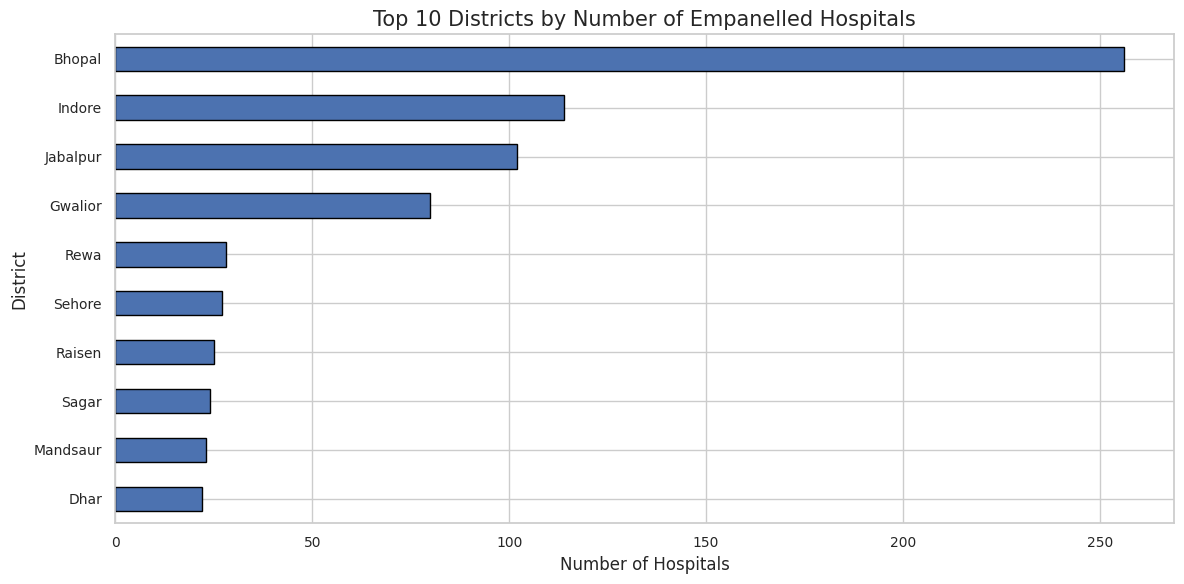

In [71]:
district_counts = df_processed['District'].value_counts().head(10)

plt.figure(figsize=(12, 6))
district_counts.sort_values().plot(kind='barh', edgecolor='black')

plt.title('Top 10 Districts by Number of Empanelled Hospitals', fontsize=15)
plt.xlabel('Number of Hospitals', fontsize=12)
plt.ylabel('District', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

###7.1 Analysis of Top 10 Districts

The bar chart shows the top 10 districts with the highest number of empanelled hospitals in Madhya Pradesh.

* Bhopal has the highest number of hospitals (256).
* Indore ranks second with 114 hospitals.
* Jabalpur has 102 hospitals, followed by Gwalior with 80.
* A significant gap exists between the top four districts and the remaining districts.
* This indicates that empanelled hospitals are concentrated in a few major districts.

The distribution highlights regional differences in the availability of empanelled hospitals.

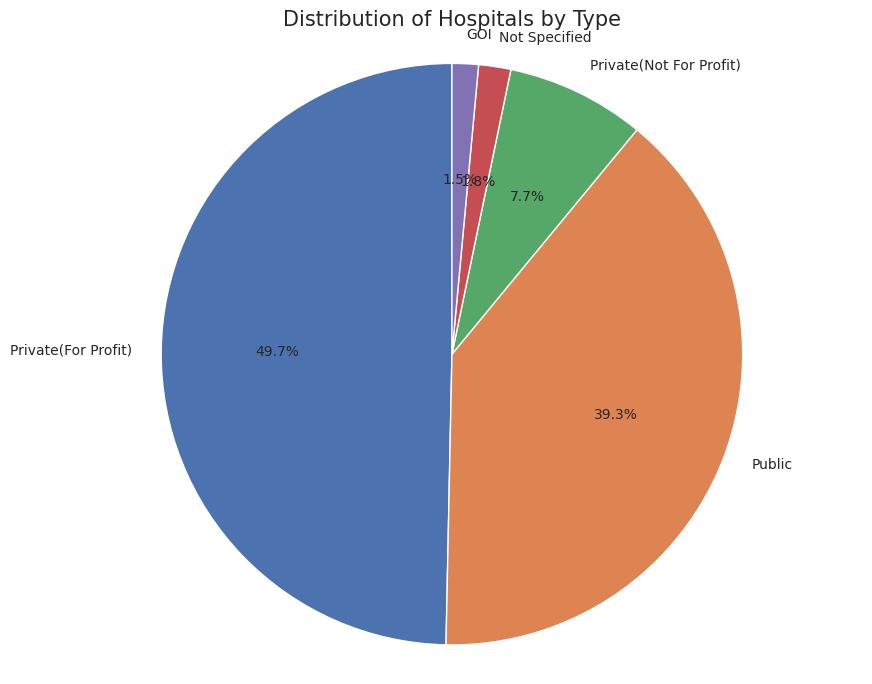

In [72]:
hospital_type_counts = df_processed['Hospital Type'].value_counts()

plt.figure(figsize=(9, 7))

plt.pie(
    hospital_type_counts,
    labels=hospital_type_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 10}
)

plt.title('Distribution of Hospitals by Type', fontsize=15)
plt.axis('equal')
plt.tight_layout()
plt.show()

###7.2 Analysis of Hospital Type Distribution

The pie chart represents the distribution of empanelled hospitals by hospital type.

* Private (For Profit) hospitals form the largest share at 49.7% (611 hospitals).
* Public hospitals account for 39.3% (484 hospitals).
* Private (Not For Profit) hospitals represent 7.7% (95 hospitals).
* GOI hospitals account for approximately 1.5% (18 hospitals).
* Not Specified hospitals make up the remaining 1.8% (22 hospitals).

The analysis shows that private (for-profit) hospitals constitute the largest category, while public hospitals also represent a significant share.

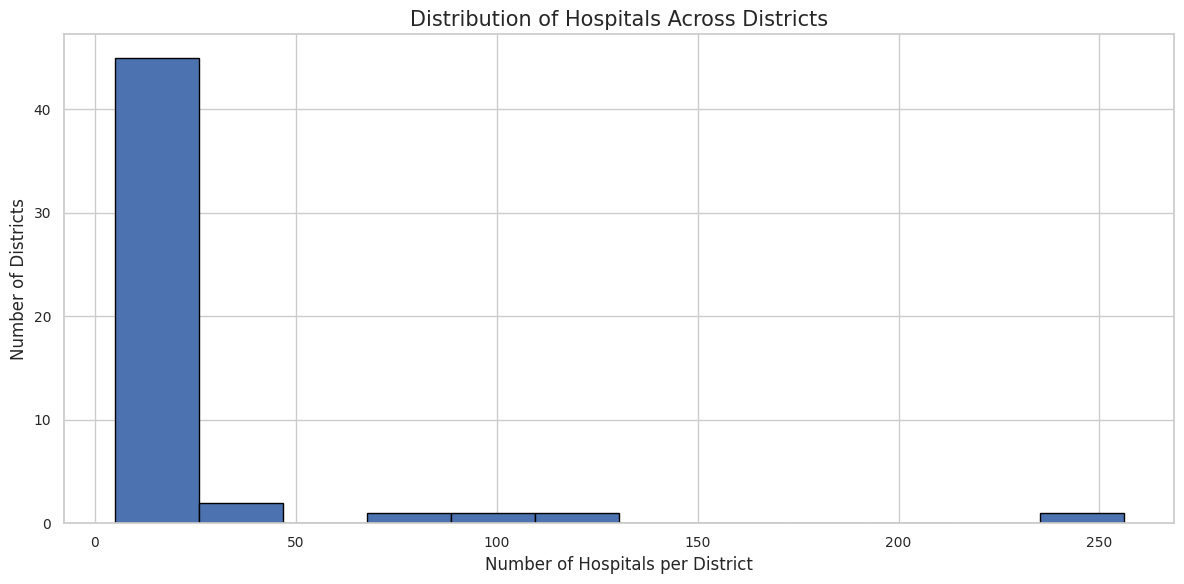

In [73]:
plt.figure(figsize=(12, 6))

plt.hist(
    df_processed.groupby('District').size(),
    bins=12,
    edgecolor='black'
)

plt.title('Distribution of Hospitals Across Districts', fontsize=15)
plt.xlabel('Number of Hospitals per District', fontsize=12)
plt.ylabel('Number of Districts', fontsize=12)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()


###7.3 Analysis of District-wise Hospital Distribution

The histogram shows the distribution of hospitals across the 51 districts of Madhya Pradesh.

* The X-axis represents the number of hospitals per district.
* The Y-axis represents the number of districts within each hospital-count range.
* The histogram helps identify how hospital availability varies across districts.
* It shows whether hospitals are evenly distributed or concentrated in a smaller number of districts.

This analysis helps identify differences in healthcare infrastructure across districts.

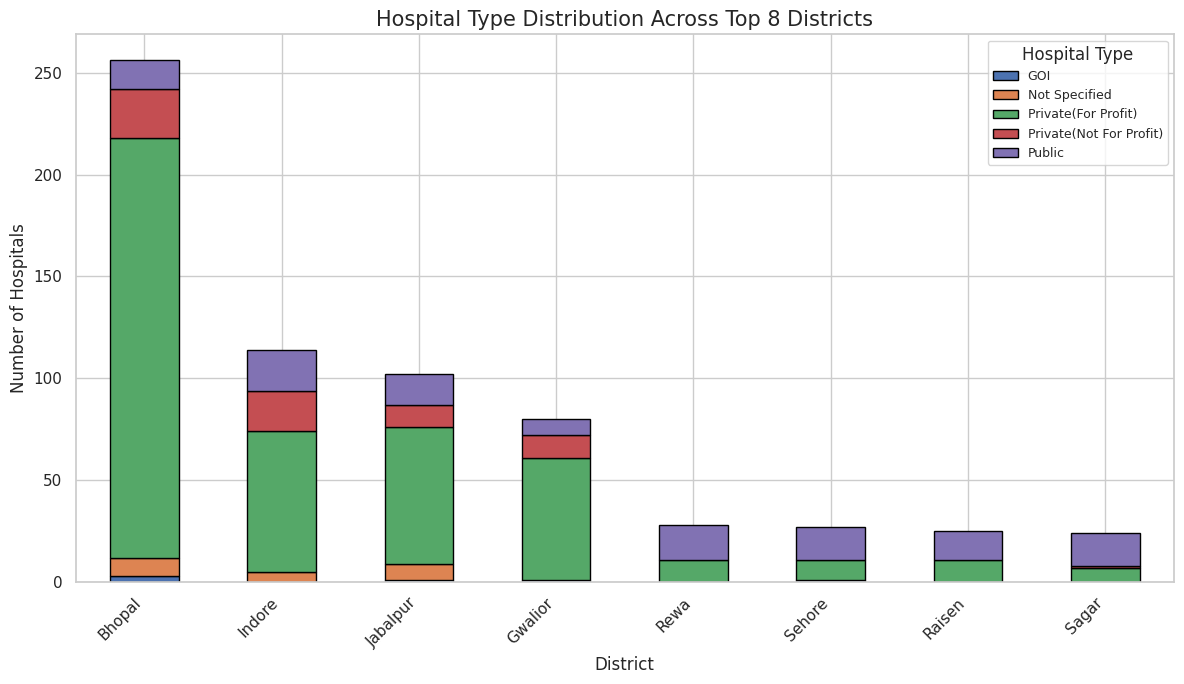

In [74]:
top_8_districts = df_processed['District'].value_counts().head(8).index

district_type = pd.crosstab(
    df_processed[df_processed['District'].isin(top_8_districts)]['District'],
    df_processed[df_processed['District'].isin(top_8_districts)]['Hospital Type']
)

district_type = district_type.loc[
    df_processed['District'].value_counts().head(8).index
]

district_type.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 7),
    edgecolor='black'
)

plt.title('Hospital Type Distribution Across Top 8 Districts', fontsize=15)
plt.xlabel('District', fontsize=12)
plt.ylabel('Number of Hospitals', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Hospital Type', fontsize=9)
plt.tight_layout()
plt.show()

###7.4 Hospital Type Distribution Across Top 8 Districts – Analysis

The stacked bar chart compares the distribution of different hospital types across the top 8 districts with the highest number of empanelled hospitals.

It shows the contribution of public and private hospitals in each district and highlights differences in hospital-type distribution across these districts.

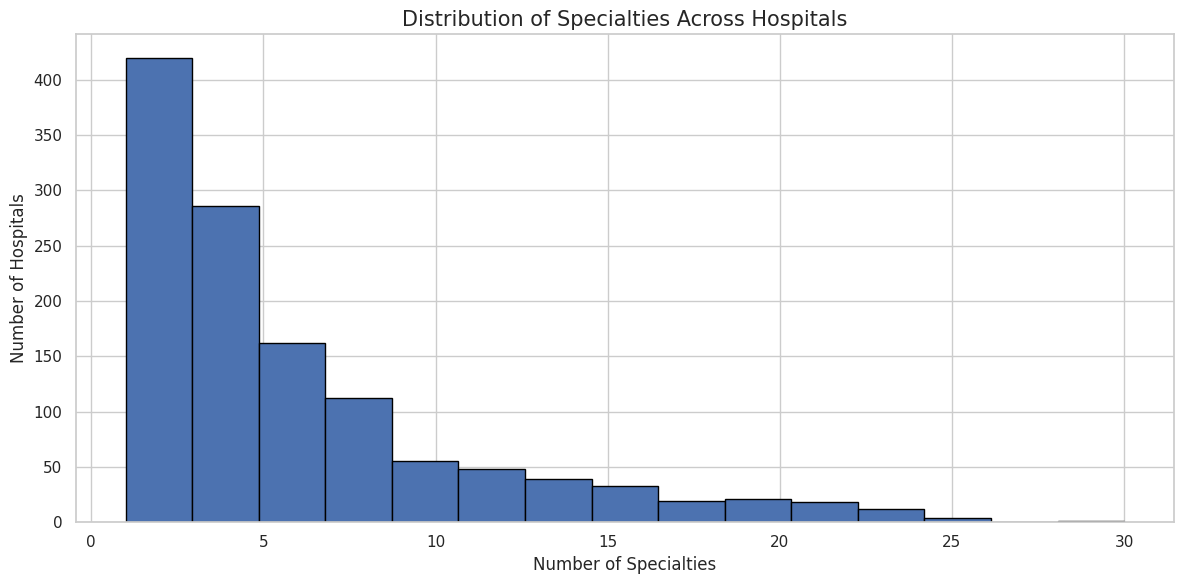

In [75]:
specialty_counts = df_processed['Num Specialities']

plt.figure(figsize=(12, 6))

plt.hist(
    specialty_counts,
    bins=15,
    edgecolor='black'
)

plt.title('Distribution of Specialties Across Hospitals', fontsize=15)
plt.xlabel('Number of Specialties', fontsize=12)
plt.ylabel('Number of Hospitals', fontsize=12)
plt.tight_layout()
plt.show()

###7.5 Distribution of Specialties Across Hospitals – Analysis

The histogram shows the distribution of the number of specialties available across empanelled hospitals.

It helps understand how healthcare facilities vary in terms of their specialty coverage. The distribution also highlights differences between hospitals offering fewer specialties and those offering a wider range of specialties.

In [76]:
print("Sample Specialty Values:")
display(df_processed['Specialities'].head(10))

print("\nM Codes:")
display(df_processed['M Codes'].head(10))

print("\nS Codes:")
display(df_processed['S Codes'].head(10))

Sample Specialty Values:


,Specialities
0,"M1, M7, M2, S1, S14, S16, S2, S3, S4, S5"
1,"M1, M7, M2, S1, S16, S2, S3, S4, S5"
2,"M1, M7, M2, M3, M8, S1, S10, S11, S12, S14, S1..."
3,"M1, M2, S8, M7, S7, M3, M4, M5, M6, M8, S1, S1..."
4,"M1, M2, S8, M7, S7, M3, M4, M5, M6, M8, S1, S1..."
5,"M1, M7, M2, S1, S16, S2, S3, S4, S5, S6"
6,"M1, M7, S7, M2, M8, S1, S10, S11, S14, S2, S3,..."
7,"M1, M2, S8, M7, S7, M3, M4, M5, M6, M8, S1, S1..."
8,M8
9,"M1, M7, M2, S1, S4"



M Codes:


,M Codes
0,"M1, M7, M2"
1,"M1, M7, M2"
2,"M1, M7, M2, M3, M8"
3,"M1, M2, M7, M3, M4, M5, M6, M8"
4,"M1, M2, M7, M3, M4, M5, M6, M8"
5,"M1, M7, M2"
6,"M1, M7, M2, M8"
7,"M1, M2, M7, M3, M4, M5, M6, M8"
8,M8
9,"M1, M7, M2"



S Codes:


,S Codes
0,"S1, S14, S16, S2, S3, S4, S5"
1,"S1, S16, S2, S3, S4, S5"
2,"S1, S10, S11, S12, S14, S16, S2, S3, S4, S5, S..."
3,"S8, S7, S1, S10, S11, S12, S13, S14, S15, S16,..."
4,"S8, S7, S1, S10, S11, S12, S14, S15, S16, S2, ..."
5,"S1, S16, S2, S3, S4, S5, S6"
6,"S7, S1, S10, S11, S14, S2, S3, S4, S5, S8, S9"
7,"S8, S7, S1, S10, S11, S12, S13, S14, S15, S16,..."
8,
9,"S1, S4"


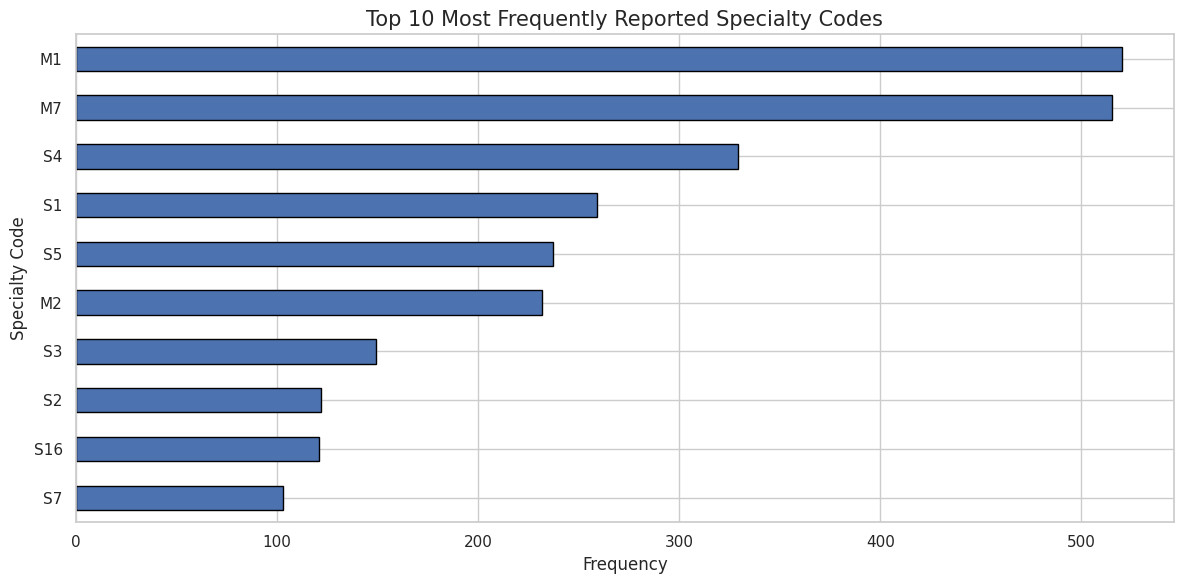

,0
M1,520
M7,515
S4,329
S1,259
S5,237
M2,232
S3,149
S2,122
S16,121
S7,103


In [77]:
import re
from collections import Counter

all_codes = df_processed['Specialities'].dropna().apply(
    lambda x: re.findall(r'\b[MS]\d+\b', str(x))
)

code_counts = Counter(
    code for codes in all_codes for code in codes
)

top_10_codes = pd.Series(code_counts).sort_values(ascending=False).head(10)

plt.figure(figsize=(12, 6))
top_10_codes.sort_values().plot(kind='barh', edgecolor='black')
plt.title('Top 10 Most Frequently Reported Specialty Codes', fontsize=15)
plt.xlabel('Frequency', fontsize=12)
plt.ylabel('Specialty Code', fontsize=12)
plt.tight_layout()
plt.show()

display(top_10_codes)

###7.6 Top 10 Most Frequently Reported Specialty Codes – Analysis

The bar chart shows the 10 most frequently reported specialty codes across empanelled hospitals.

M1 is the most frequently reported code, with 520 occurrences, closely followed by M7 with 515 occurrences. S4 ranks third with 329 occurrences. Other frequently reported codes include S1 (259), S5 (237), and M2 (232).

The results show that M1 and M7 are the most commonly reported specialty codes in the dataset. This analysis helps identify the specialty codes that appear most frequently across empanelled hospitals.

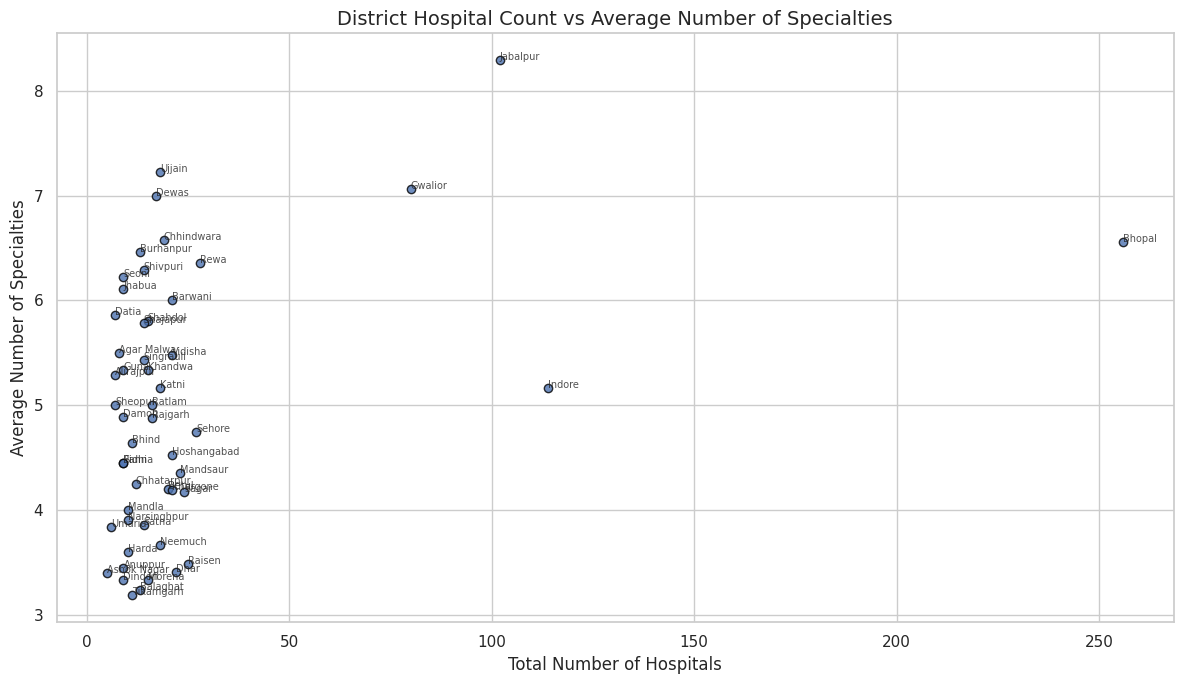

,District,Total_Hospitals,Average_Specialties
8,Bhopal,256,6.554688
21,Indore,114,5.166667
22,Jabalpur,102,8.294118
18,Gwalior,80,7.062500
36,Rewa,28,6.357143
39,Sehore,27,4.740741
33,Raisen,25,3.480000
37,Sagar,24,4.166667
28,Mandsaur,23,4.347826
15,Dhar,22,3.409091


In [78]:
district_analysis = df_processed.groupby('District').agg(
    Total_Hospitals=('Hospital Id', 'count'),
    Average_Specialties=('Num Specialities', 'mean')
).reset_index()

plt.figure(figsize=(12, 7))
plt.scatter(
    district_analysis['Total_Hospitals'],
    district_analysis['Average_Specialties'],
    edgecolor='black',
    alpha=0.8
)

for _, row in district_analysis.iterrows():
    plt.annotate(
        row['District'],
        (row['Total_Hospitals'], row['Average_Specialties']),
        fontsize=7,
        alpha=0.8
    )

plt.title('District Hospital Count vs Average Number of Specialties', fontsize=14)
plt.xlabel('Total Number of Hospitals', fontsize=12)
plt.ylabel('Average Number of Specialties', fontsize=12)
plt.tight_layout()
plt.show()

display(district_analysis.sort_values('Total_Hospitals', ascending=False).head(10))

###7.7 District Hospital Count vs Average Number of Specialties – Analysis

The scatter plot examines the relationship between the number of empanelled hospitals and the average number of specialties across 51 districts.

Bhopal has the highest number of hospitals (256), with an average of 6.55 specialties. Jabalpur has 102 hospitals and a higher average of 8.29 specialties. Gwalior has 80 hospitals with an average of 7.06 specialties, while Indore has 114 hospitals with an average of 5.17 specialties.

The chart indicates that districts with more hospitals do not necessarily have a higher average number of specialties. Hospital count and specialty availability vary across districts.

In [79]:
numeric_df = df_processed.select_dtypes(include='number').copy()

if 'Hospital Id' in numeric_df.columns:
    numeric_df.drop(columns=['Hospital Id'], inplace=True)

print("Numerical Columns for Correlation:")
print(numeric_df.columns.tolist())

print("\nCorrelation Matrix:")
display(numeric_df.corr())

Numerical Columns for Correlation:
['Sno', 'Hospital Contact', 'Num Specialities']

Correlation Matrix:


,Sno,Hospital Contact,Num Specialities
Sno,1.000000,-0.104565,0.025115
Hospital Contact,-0.104565,1.000000,-0.026873
Num Specialities,0.025115,-0.026873,1.000000


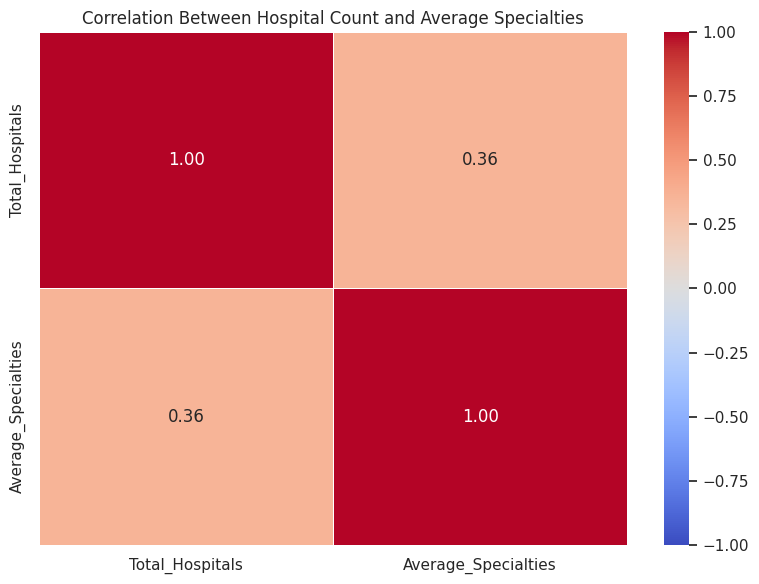

,Total_Hospitals,Average_Specialties
Total_Hospitals,1.000000,0.356761
Average_Specialties,0.356761,1.000000


In [80]:
district_corr = district_analysis[
    ['Total_Hospitals', 'Average_Specialties']
].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    district_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Between Hospital Count and Average Specialties')
plt.tight_layout()
plt.show()

display(district_corr)

###7.8 Correlation Between Hospital Count and Average Specialties – Analysis

The correlation heatmap shows a correlation coefficient of approximately 0.36 between the total number of hospitals and the average number of specialties across districts.

This indicates a weak-to-moderate positive relationship between the two variables. Districts with more hospitals tend to show a slight increase in average specialty availability, but the relationship is not strong.

The analysis suggests that a higher number of hospitals does not automatically guarantee a higher average number of specialties.

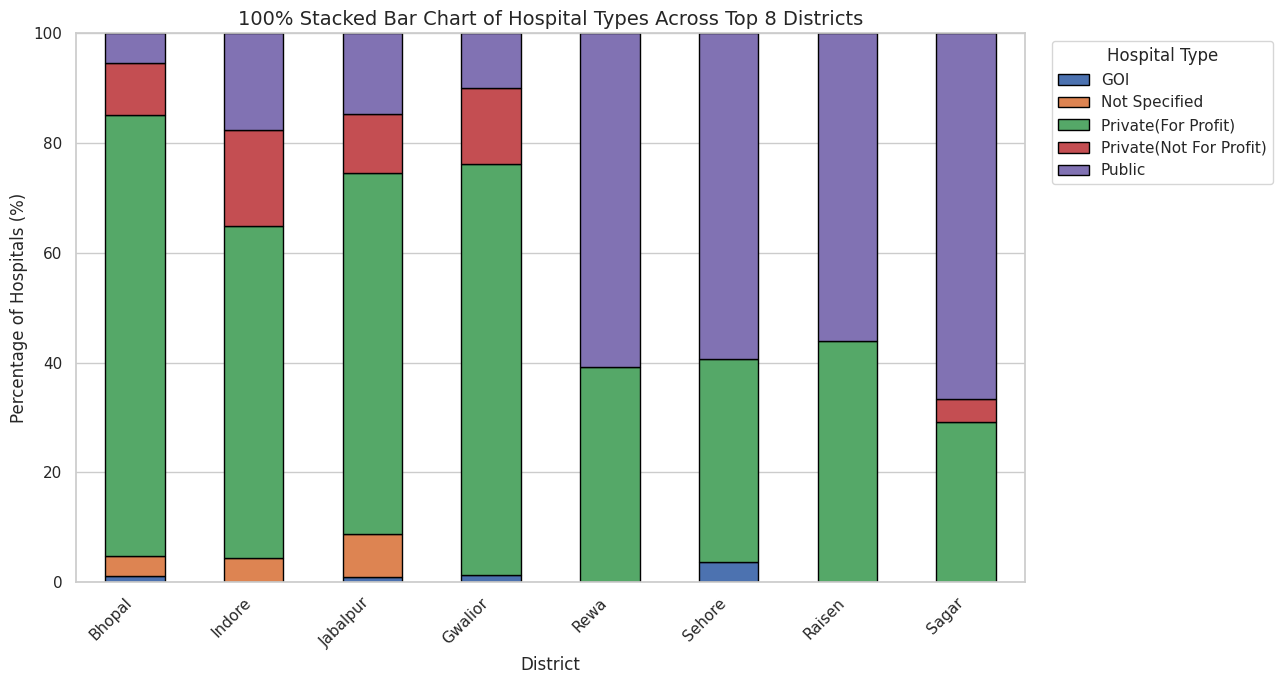

Hospital Type,GOI,Not Specified,Private(For Profit),Private(Not For Profit),Public
District,,,,,
Bhopal,1.17,3.52,80.47,9.38,5.47
Indore,0.00,4.39,60.53,17.54,17.54
Jabalpur,0.98,7.84,65.69,10.78,14.71
Gwalior,1.25,0.00,75.00,13.75,10.00
Rewa,0.00,0.00,39.29,0.00,60.71
Sehore,3.70,0.00,37.04,0.00,59.26
Raisen,0.00,0.00,44.00,0.00,56.00
Sagar,0.00,0.00,29.17,4.17,66.67


In [81]:
top_8_districts = df_processed['District'].value_counts().head(8).index

district_type_percent = pd.crosstab(
    df_processed[df_processed['District'].isin(top_8_districts)]['District'],
    df_processed[df_processed['District'].isin(top_8_districts)]['Hospital Type'],
    normalize='index'
) * 100

district_type_percent = district_type_percent.loc[top_8_districts]

district_type_percent.plot(
    kind='bar',
    stacked=True,
    figsize=(13, 7),
    edgecolor='black'
)

plt.title('100% Stacked Bar Chart of Hospital Types Across Top 8 Districts', fontsize=14)
plt.xlabel('District', fontsize=12)
plt.ylabel('Percentage of Hospitals (%)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Hospital Type', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

display(district_type_percent.round(2))

###7.9 100% Stacked Bar Chart of Hospital Types Across Top 8 Districts – Analysis

The 100% stacked bar chart compares the percentage distribution of hospital types across the top 8 districts.

Bhopal has the highest proportion of Private (For Profit) hospitals at 80.47%, followed by Gwalior at 75% and Jabalpur at 65.69%.

In contrast, Sagar has the highest proportion of Public hospitals at 66.67%, followed by Rewa at 60.71% and Sehore at 59.26%.

Indore has a relatively balanced distribution, with Private (For Profit) and Public hospitals each accounting for 60.53% and 17.54%, respectively, while Private (Not For Profit) hospitals account for 17.54%.

The chart highlights significant differences in hospital ownership patterns across districts and shows that the distribution of public and private healthcare facilities is not uniform.

## 8. STATISTICAL ANALYSIS
### 8.1 Descriptive Statistical Analysis – Interpretation

The descriptive statistical analysis examines the number of specialties available across 1,230 empanelled hospitals.

The average number of specialties is 5.67, while the median is 4 and the mode is 1. This indicates that the typical hospital offers fewer specialties than the overall average.

The standard deviation is 5.29, showing considerable variation in specialty availability across hospitals. The number of specialties ranges from a minimum of 1 to a maximum of 30.

The first quartile is 2 and the third quartile is 7.75, meaning that the middle 50% of hospitals have approximately 2 to 8 specialties.

Overall, the results indicate considerable differences in the range of specialties offered by empanelled hospitals.

In [82]:
specialty_stats = df_processed['Num Specialities'].describe()

print("Descriptive Statistical Analysis of Number of Specialties")
display(specialty_stats)

print("Mean:", df_processed['Num Specialities'].mean())
print("Median:", df_processed['Num Specialities'].median())
print("Mode:", df_processed['Num Specialities'].mode().tolist())
print("Standard Deviation:", df_processed['Num Specialities'].std())
print("Variance:", df_processed['Num Specialities'].var())
print("Minimum:", df_processed['Num Specialities'].min())
print("Maximum:", df_processed['Num Specialities'].max())

Descriptive Statistical Analysis of Number of Specialties


,Num Specialities
count,1230.000000
mean,5.674797
std,5.291035
min,1.000000
25%,2.000000
50%,4.000000
75%,7.750000
max,30.000000


Mean: 5.67479674796748
Median: 4.0
Mode: [1]
Standard Deviation: 5.291035043362988
Variance: 27.995051830095175
Minimum: 1
Maximum: 30


### 8.2 Correlation Analysis – Interpretation

Correlation analysis examines the relationship between the total number of hospitals and the average number of specialties across districts.

The Pearson correlation coefficient measures the strength and direction of the linear relationship between these two variables.

A positive correlation indicates that districts with more hospitals tend to have a higher average number of specialties, while a negative correlation indicates an inverse relationship.

This analysis helps understand whether hospital availability is associated with specialty availability across districts.

In [83]:
correlation_value = district_analysis[
    'Total_Hospitals'
].corr(district_analysis['Average_Specialties'])

print("Pearson Correlation Coefficient:", round(correlation_value, 3))

if correlation_value > 0:
    print("There is a positive relationship between the two variables.")
elif correlation_value < 0:
    print("There is a negative relationship between the two variables.")
else:
    print("There is no linear relationship between the two variables.")

Pearson Correlation Coefficient: 0.357
There is a positive relationship between the two variables.


### 8.2  Results and Interpretation

The Pearson correlation coefficient between the total number of hospitals and the average number of specialties across districts is 0.357.

This indicates a weak-to-moderate positive correlation between the two variables. It suggests that districts with a higher number of hospitals tend to have slightly higher average specialty availability.

However, the relationship is not strong, which means that the number of hospitals alone does not determine the average number of specialties available in a district.

## 9. KEY FINDINGS
The analysis of 1,230 empanelled hospitals across 51 districts of Madhya Pradesh reveals the following key findings:

1. District Distribution: Bhopal has the highest number of hospitals (256), followed by Indore (114) and Jabalpur (102).
2. Hospital Type Distribution: Private (For Profit) hospitals form the largest category with 611 hospitals (49.7%), followed by Public hospitals with 484 (39.3%).
3. Specialty Availability: Hospitals offer an average of 5.67 specialties, with the number ranging from 1 to 30.
4. Frequently Reported Specialty Codes: M1 (520 occurrences) and M7 (515 occurrences) are the most frequently reported specialty codes.
5. District-Level Variation: Jabalpur has an average of 8.29 specialties per hospital, compared with 6.55 in Bhopal.
6. Correlation Analysis: The correlation coefficient between district hospital count and average specialties is 0.357, indicating a weak-to-moderate positive relationship.
7. Hospital Ownership Patterns: The proportion of public and private hospitals varies considerably across districts.

## 10. CONCLUSION

This project presents a data-driven analysis of 1,230 empanelled hospitals across 51 districts of Madhya Pradesh under the Ayushman Bharat healthcare programme.

The analysis highlights the distribution of hospitals, hospital ownership patterns, and availability of medical specialties across different districts.

The findings show that Bhopal has the highest number of empanelled hospitals, while Jabalpur has a higher average number of specialties than Bhopal. Private (For Profit) hospitals represent the largest hospital category in the dataset.

The statistical analysis shows an average of 5.67 specialties per hospital. The correlation analysis indicates a weak-to-moderate positive relationship between district hospital count and average specialty availability, with a coefficient of 0.357.

Overall, this project demonstrates how data analytics and visualization can help understand healthcare infrastructure and identify variations in hospital distribution and specialty availability across Madhya Pradesh.

## 11. FUTURE SCOPE

The project can be further expanded in the following ways:

1. Regular Data Updates: Future analysis can use updated hospital records to monitor changes in healthcare infrastructure.
2. Geographical Analysis: District-wise maps can be developed to visualize the distribution of empanelled hospitals across Madhya Pradesh.
3. Specialty Analysis: Further studies can examine the availability of specific medical specialties across districts.
4. Healthcare Accessibility: Hospital distribution can be studied along with population data to understand healthcare accessibility.
5. Comparative Analysis: Similar analysis can be conducted for other states to compare healthcare infrastructure and hospital distribution.
6. Interactive Dashboards: An interactive dashboard can be developed to help users explore hospital distribution, hospital types, and specialty availability.

These improvements can provide a broader understanding of healthcare infrastructure and support better data-driven planning.

## 12. REFERENCES

1. Ayushman Bharat PM-JAY – Hospital Empanelment Dashboard
    https://insights.pmjay.gov.in/
2. National Health Authority – Madhya Pradesh State Factsheet
    https://nha.gov.in/img/pmjay-files/State-factsheet-for-September-2021/Madhya-Pradesh-state-factsheet-september-2021-16.pdf
3. Ayushman Bharat Hospital Empanelment – Research Dataset and Methodology
    https://pmc.ncbi.nlm.nih.gov/articles/PMC8158976/
4. Ayushman Bharat Hospital List – Madhya Pradesh
    https://hospitals.pmjay.gov.in/